# DS Average Time Drift Analysis across 2022 Runs

This notebook analyzes the **$t_0^{\mathrm{DS}}$ distribution** (`reft-DS` histogram) across all available 2022 runs in `/eos/user/i/idioniso/Timing/`.

### Objectives:
1. Superimpose the $t_0^{\mathrm{DS}}$ distributions for all available runs in a single figure with color encoding by run number.
2. Characterize the LHC bunch timing structure and monitor clock phase drifts across runs.
3. Quantify the fraction of accepted muon events for different selection windows (static vs. dynamic mode).


In [ ]:
import os
import pandas as pd
import glob
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import uproot
import ddfUtils.mpl_styling as dms

# Prevent JupyROOT RCanvas crash in notebook environments
try:
    import ROOT
    ROOT.gROOT.SetBatch(True)
    import ROOT._jupyroot.helpers.utils as jutils
    jutils.RCanvasAvailable = lambda: False
except Exception:
    pass

# Set default font and style
plt.rcParams.update({
    "font.size": 13,
    "axes.labelsize": 15,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 12,
    "figure.titlesize": 16,
})
print("Environment and libraries initialized successfully.")


In [ ]:
import os
import uproot
import numpy as np

# ------------------------------------------------------------------------------
# Load reference time distributions from consolidated reference_times_2022.root
# Structure:
#   <catI | catII>/runXXXX/
#     ├── reft-DS
#     └── reft-SF
# ------------------------------------------------------------------------------
ref_root_path = "/eos/user/i/idioniso/Timing/reference_times_2022.root"

def load_category_runs(root_path, hist_name="reft-DS", min_entries=50):
    """Load reference time distributions for catI and catII from the consolidated ROOT file."""
    if not os.path.exists(root_path):
        print(f"[WARNING] {root_path} not found yet. It will load once ref_times.py finishes!")
        return {"catI": [], "catII": []}
    
    data_by_cat = {"catI": [], "catII": []}
    
    with uproot.open(root_path) as f:
        for cat in ["catI", "catII"]:
            if cat not in f:
                print(f"[INFO] Directory '{cat}' not found in {root_path}.")
                continue
            
            cat_dir = f[cat]
            for run_key in cat_dir.keys(cycle=False):
                try:
                    rnum = int(run_key.replace("run00", "").replace("run0", "").replace("run", ""))
                except ValueError:
                    continue
                
                full_hpath = f"{cat}/{run_key}/{hist_name}"
                if full_hpath not in f:
                    continue
                
                counts, edges = f[full_hpath].to_numpy()
                total = counts.sum()
                if total < min_entries:
                    continue
                
                centers = 0.5 * (edges[:-1] + edges[1:])
                mode_idx = np.argmax(counts)
                mode_t = centers[mode_idx]
                peak_val = counts[mode_idx]
                
                data_by_cat[cat].append({
                    "run": rnum,
                    "edges": edges,
                    "centers": centers,
                    "counts": counts,
                    "norm_peak": counts / peak_val if peak_val > 0 else counts,
                    "norm_area": counts / total if total > 0 else counts,
                    "total": total,
                    "mode_t": mode_t,
                    "peak_val": peak_val,
                    "mode_err": 0.5 * (edges[1] - edges[0]),
                })
            
            data_by_cat[cat].sort(key=lambda d: d["run"])
            print(f"Loaded {len(data_by_cat[cat])} runs for {cat} ({hist_name}).")
            if data_by_cat[cat]:
                print(f"  -> {cat} run range: {data_by_cat[cat][0]['run']} to {data_by_cat[cat][-1]['run']}")
                
    return data_by_cat

# Load DS reference time distributions for Cat I and Cat II
runs_by_cat = load_category_runs(ref_root_path, hist_name="reft-DS")
runs_data_catI = runs_by_cat["catI"]
runs_data_catII = runs_by_cat["catII"]


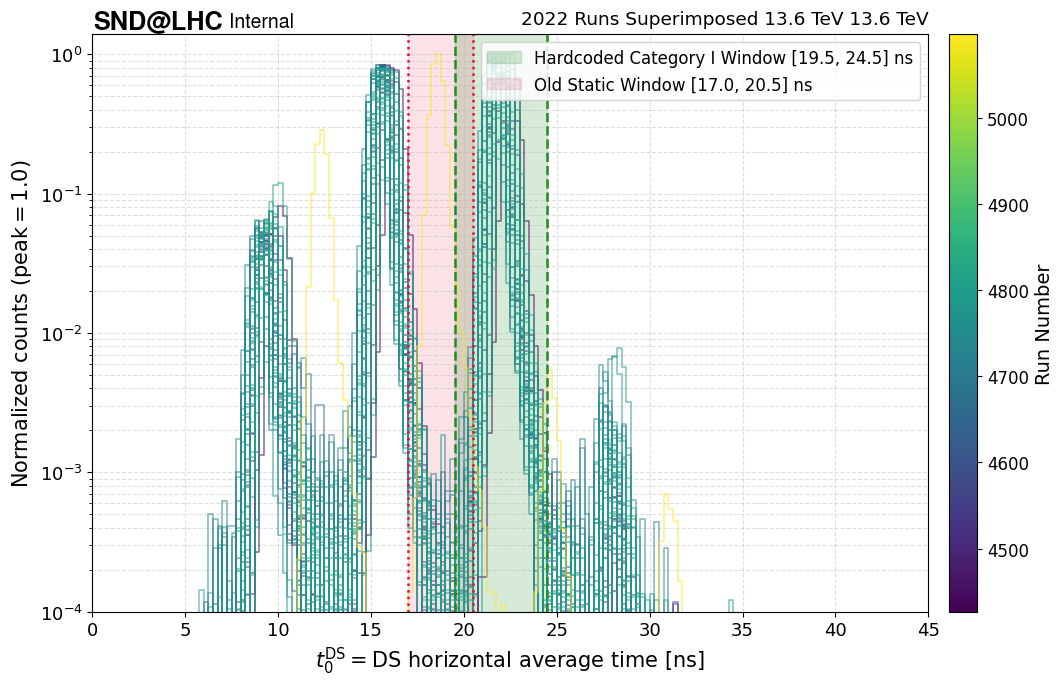

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7.5), sharey=True)

panels = [
    ("Category I", runs_data_catI, axes[0], cm.viridis, [19.5, 24.5], "forestgreen"),
    ("Category II", runs_data_catII, axes[1], cm.plasma, None, None)
]

for title, rdata, ax, cmap, win, win_col in panels:
    if not rdata:
        ax.text(0.5, 0.5, f"No runs loaded for {title}", transform=ax.transAxes,
                ha="center", va="center", fontsize=14, color="gray")
        ax.set_title(title, fontsize=15, pad=10)
        ax.set_xlabel(r"$t_0^{\mathrm{DS}}$ = DS horizontal average time [ns]", fontsize=14)
        ax.grid(True, which="both", linestyle="--", alpha=0.35)
        continue

    run_numbers = [d["run"] for d in rdata]
    min_run, max_run = min(run_numbers), max(run_numbers)
    norm = mcolors.Normalize(vmin=min_run, vmax=max(max_run, min_run + 1))

    # Plot each run with color mapped to run number
    for d in rdata:
        color = cmap(norm(d["run"]))
        ax.step(d["edges"][:-1], d["norm_peak"], where="post", color=color, alpha=0.55, lw=1.2)

    # Shaded reference window if applicable
    if win:
        w_low, w_high = win
        ax.axvspan(w_low, w_high, color=win_col, alpha=0.18,
                  label=f"{title} Window [{w_low}, {w_high}] ns")
        ax.axvline(w_low, color=win_col, linestyle="--", lw=1.8)
        ax.axvline(w_high, color=win_col, linestyle="--", lw=1.8)

    ax.set_yscale("log")
    ax.set_ylim(1e-4, 1.5)
    ax.set_xlim(0, 45)
    ax.set_xlabel(r"$t_0^{\mathrm{DS}}$ = DS horizontal average time [ns]", fontsize=14)
    ax.set_title(f"{title} (N = {len(rdata)} runs)", fontsize=15, pad=10)
    ax.grid(True, which="both", linestyle="--", alpha=0.35)

    # Individual colorbar per panel
    sm = cm.ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax, pad=0.02)
    cbar.set_label("Run Number", fontsize=13)

    if win:
        ax.legend(loc="upper right", frameon=True, fontsize=11)

axes[0].set_ylabel("Normalized counts (peak = 1.0)", fontsize=14)

# Add experiment label
dms.add_label(mainText="SND@LHC", extraText="Internal", suppText="2022 Reference Time Distributions", ax=axes[0])

plt.tight_layout()
plt.show()


In [ ]:
fig, ax = plt.subplots(figsize=(12, 5.5))

if runs_data_catI:
    runs_I = [d["run"] for d in runs_data_catI]
    modes_I = [d["mode_t"] for d in runs_data_catI]
    mode_errs_I = [d["mode_err"] for d in runs_data_catI]
    ax.errorbar(runs_I, modes_I, yerr=mode_errs_I, fmt="o", color="navy", ecolor="navy",
                elinewidth=1.2, capsize=2.5, markersize=5, markeredgecolor="black",
                zorder=3, label="Cat I Main Peak Mode")
    ax.plot(runs_I, modes_I, color="navy", linestyle="--", alpha=0.5, lw=1)

if runs_data_catII:
    runs_II = [d["run"] for d in runs_data_catII]
    modes_II = [d["mode_t"] for d in runs_data_catII]
    mode_errs_II = [d["mode_err"] for d in runs_data_catII]
    ax.errorbar(runs_II, modes_II, yerr=mode_errs_II, fmt="s", color="crimson", ecolor="crimson",
                elinewidth=1.2, capsize=2.5, markersize=5, markeredgecolor="black",
                zorder=3, label="Cat II Main Peak Mode")
    ax.plot(runs_II, modes_II, color="crimson", linestyle="--", alpha=0.5, lw=1)

ax.set_xlabel("Run Number", fontsize=14)
ax.set_ylabel(r"Mode $t_0^{\mathrm{DS}}$ [ns]", fontsize=14)
ax.grid(True, linestyle="--", alpha=0.5)

dms.add_label(mainText="SND@LHC", extraText="Internal", suppText="Peak Mode Drift (2022)", ax=ax)
ax.legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.show()


In [ ]:
# Compare event acceptance for hardcoded Category I window [19.5, 24.5] vs old [17.0, 20.5]
def get_acceptance(d, t_min, t_max):
    mask = (d["centers"] >= t_min) & (d["centers"] <= t_max)
    return 100.0 * d["counts"][mask].sum() / d["total"]

acc_hardcoded = [get_acceptance(d, 19.5, 24.5) for d in runs_data]
acc_old_static = [get_acceptance(d, 17.0, 20.5) for d in runs_data]

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(runs, acc_hardcoded, marker="o", color="forestgreen", lw=1.8, label=r"Category I Window $[19.5, 24.5]$ ns")
ax.plot(runs, acc_old_static, marker="s", color="crimson", lw=1.8, label=r"Old Static Window $[17.0, 20.5]$ ns")

ax.set_xlabel("Run Number", fontsize=14)
ax.set_ylabel("Accepted Events [%]", fontsize=14)
ax.set_ylim(0, 100)
ax.grid(True, linestyle="--", alpha=0.5)

dms.add_label(mainText="SND@LHC", extraText="Internal", suppText="Event Selection Acceptance", ax=ax)

ax.legend(loc="center right", frameon=True)
plt.tight_layout()
plt.show()

mean_hc = np.mean(acc_hardcoded)
min_hc, max_hc = np.min(acc_hardcoded), np.max(acc_hardcoded)
mean_old = np.mean(acc_old_static)
min_old, max_old = np.min(acc_old_static), np.max(acc_old_static)

print(f"Mean acceptance with [19.5, 24.5] window: {mean_hc:.1f}% (min: {min_hc:.1f}%, max: {max_hc:.1f}%)")
print(f"Mean acceptance with Old [17.0, 20.5] window: {mean_old:.1f}% (min: {min_old:.1f}%, max: {max_old:.1f}%)")


---
# Calibration Constants Drift Analysis

This section analyzes whether the timing calibration constants drift across 2022 runs or remain stable.
It examines:
1. **$c_{\mathrm{scint}}$** (effective signal speed in scintillator, cm/ns)
2. **Fine Alignment Offsets** (relative channel-to-channel time alignment, ns)
3. **Time-Walk Parameters** ($t_0$ and $\alpha$ / shape terms)

Constants are parsed from `/eos/user/i/idioniso/Timing/run<runNr>/run<runNr>_timing_calibration.json`.

In [ ]:
# Load consolidated calibration constants for the selected Category I runs
calib_runs = []

for rd in run_dirs:
    bname = os.path.basename(rd)
    try:
        rnum = int(bname.replace("run00", "").replace("run0", "").replace("run", ""))
    except ValueError:
        continue
    
    if selected_runs_set is not None and rnum not in selected_runs_set:
        continue
        
    calib_json = os.path.join(rd, f"{bname}_timing_calibration.json")
    if not os.path.exists(calib_json):
        continue
        
    with open(calib_json) as jf:
        cdata = json.load(jf)
    
    # Extract SF summary statistics
    sf_cscint_dict = cdata.get("SF", {}).get("cscint", {})
    sf_align_dict = cdata.get("SF", {}).get("alignment", {})
    sf_tw_dict = cdata.get("SF", {}).get("timewalk", {})
    
    cscint_vals = [v[0] for v in sf_cscint_dict.values() if isinstance(v, list) and len(v) >= 1]
    align_vals = [v[0] for v in sf_align_dict.values() if isinstance(v, list) and len(v) >= 1]
    tw_t0_vals = [v["t0"] for v in sf_tw_dict.values() if isinstance(v, dict) and "t0" in v]
    tw_alpha_vals = [v["alpha"] for v in sf_tw_dict.values() if isinstance(v, dict) and "alpha" in v]
    
    n_c = len(cscint_vals)
    n_a = len(align_vals)
    n_tw = len(tw_t0_vals)
    
    calib_runs.append({
        "run": rnum,
        "cat": "I",
        "sf_cscint": sf_cscint_dict,
        "sf_align": sf_align_dict,
        "sf_tw": sf_tw_dict,
        "cscint_mean": np.mean(cscint_vals) if n_c else np.nan,
        "cscint_std": np.std(cscint_vals) if n_c else np.nan,
        "cscint_sem": np.std(cscint_vals) / np.sqrt(n_c) if n_c else np.nan,
        "align_mean": np.mean(align_vals) if n_a else np.nan,
        "align_std": np.std(align_vals) if n_a else np.nan,
        "align_sem": np.std(align_vals) / np.sqrt(n_a) if n_a else np.nan,
        "tw_t0_mean": np.mean(tw_t0_vals) if n_tw else np.nan,
        "tw_t0_std": np.std(tw_t0_vals) if n_tw else np.nan,
        "tw_t0_sem": np.std(tw_t0_vals) / np.sqrt(n_tw) if n_tw else np.nan,
        "tw_alpha_mean": np.mean(tw_alpha_vals) if n_tw else np.nan,
        "tw_alpha_std": np.std(tw_alpha_vals) if n_tw else np.nan,
        "tw_alpha_sem": np.std(tw_alpha_vals) / np.sqrt(n_tw) if n_tw else np.nan,
        "n_cscint": n_c,
        "n_align": n_a,
        "n_tw": n_tw,
    })

calib_runs.sort(key=lambda x: x["run"])
print(f"Loaded calibration constants for {len(calib_runs)} filtered Category I runs (Runs {calib_runs[0]['run']} -> {calib_runs[-1]['run']}).")


In [ ]:
# Plot global SF parameters drift across runs
# Note: Error bars represent the Standard Error of the Mean (SEM = std / sqrt(N))
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

runs_arr = [c["run"] for c in calib_runs]
cats_arr = [c["cat"] for c in calib_runs]

# 1. c_scint drift
ax = axes[0]
cscint_means = [c["cscint_mean"] for c in calib_runs]
cscint_sems = [c["cscint_sem"] for c in calib_runs]
ax.errorbar(runs_arr, cscint_means, yerr=cscint_sems, fmt="o", color="steelblue", ecolor="steelblue", elinewidth=1.2, capsize=2, ms=5, label=r"Mean $c_{\mathrm{scint}}$ (SF channels, error: $\sigma_{\bar{x}}$)")
ax.set_ylabel(r"$c_{\mathrm{scint}}$ [cm/ns]")
ax.set_ylim(13.5, 15.5)
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc="upper right")
dms.add_label(ax=ax, mainText="SND@LHC", extraText="Preliminary")

# 2. Fine Alignment offset drift
ax = axes[1]
align_means = [c["align_mean"] for c in calib_runs]
align_sems = [c["align_sem"] for c in calib_runs]
ax.errorbar(runs_arr, align_means, yerr=align_sems, fmt="s", color="darkorange", ecolor="darkorange", elinewidth=1.2, capsize=2, ms=5, label=r"Mean Alignment Offset (SF, error: $\sigma_{\bar{x}}$)")
ax.set_ylabel(r"Alignment Offset [ns]")
ax.set_ylim(-11.0, -8.0)
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc="upper right")

# 3. Time-Walk t0 drift
ax = axes[2]
tw_t0_means = [c["tw_t0_mean"] for c in calib_runs]
tw_t0_sems = [c["tw_t0_sem"] for c in calib_runs]
ax.errorbar(runs_arr, tw_t0_means, yerr=tw_t0_sems, fmt="^", color="forestgreen", ecolor="forestgreen", elinewidth=1.2, capsize=2, ms=5, label=r"Mean TW $t_0$ (SF, error: $\sigma_{\bar{x}}$)")
ax.set_xlabel("Run Number")
ax.set_ylabel(r"Time-Walk $t_0$ [ns]")
ax.set_ylim(-11.0, -8.0)
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()


In [ ]:
# Track drift of specific key SciFi channels across runs
# Channel format: <detector_element_id>_<sipm_channel>
sample_channels = ["20001_0", "20002_0", "20003_0", "20004_0"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Left: c_scint per channel
ax = axes[0]
for ch in sample_channels:
    r_list, c_list, c_err = [], [], []
    for cr in calib_runs:
        if ch in cr["sf_cscint"]:
            v = cr["sf_cscint"][ch]
            if isinstance(v, list) and len(v) >= 2:
                r_list.append(cr["run"])
                c_list.append(v[0])
                c_err.append(v[1])
    if r_list:
        ax.errorbar(r_list, c_list, yerr=c_err, fmt="o-", ms=4, lw=1.2, label=f"Ch {ch}")

ax.set_xlabel("Run Number")
ax.set_ylabel(r"$c_{\mathrm{scint}}$ [cm/ns]")
ax.set_title(r"Speed of Light Stability ($c_{\mathrm{scint}}$)")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc="best", framealpha=0.8)
dms.add_label(ax=ax, mainText="SND@LHC", extraText="Preliminary")

# Right: Alignment offset per channel
ax = axes[1]
for ch in sample_channels:
    r_list, a_list, a_err = [], [], []
    for cr in calib_runs:
        if ch in cr["sf_align"]:
            v = cr["sf_align"][ch]
            if isinstance(v, list) and len(v) >= 2:
                r_list.append(cr["run"])
                a_list.append(v[0])
                a_err.append(v[1])
    if r_list:
        ax.errorbar(r_list, a_list, yerr=a_err, fmt="s-", ms=4, lw=1.2, label=f"Ch {ch}")

ax.set_xlabel("Run Number")
ax.set_ylabel(r"Alignment Offset [ns]")
ax.set_title("Fine Alignment Stability")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc="best", framealpha=0.8)
dms.add_label(ax=ax, mainText="SND@LHC", extraText="Preliminary")

plt.tight_layout()
plt.show()


In [ ]:
# Distribution of c_scint across all channels per run
fig, ax = plt.subplots(figsize=(12, 6))

box_data = []
box_labels = []
# Sample every 3rd run to keep boxplot readable
sampled_runs = calib_runs[::3]

for cr in sampled_runs:
    vals = [v[0] for v in cr["sf_cscint"].values() if isinstance(v, list) and len(v) >= 1]
    if vals:
        box_data.append(vals)
        box_labels.append(str(cr["run"]))

bp = ax.boxplot(box_data, tick_labels=box_labels, patch_artist=True, showfliers=False,
                medianprops=dict(color="red", linewidth=1.5))

for patch in bp["boxes"]:
    patch.set_facecolor("lightblue")
    patch.set_alpha(0.7)

ax.set_xlabel("Run Number (sampled)")
ax.set_ylabel(r"$c_{\mathrm{scint}}$ [cm/ns]")
ax.set_title(r"$c_{\mathrm{scint}}$ Channel Spread across Runs")
plt.xticks(rotation=45, ha="right")
ax.grid(True, linestyle="--", alpha=0.5)
dms.add_label(ax=ax, mainText="SND@LHC", extraText="Preliminary")

plt.tight_layout()
plt.show()
